PEN :- 240840116017

# **Practical - 5**

### **AIM: Analyze datasets using correlation, covariance, outlier detection, and distribution analysis.**

**Step-1: Import Required Libraries.**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Step-2: Create Dataset**

In [ ]:
# Create dataset to store information about students.
data = {
    "Student_ID" : [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115],
    "Study_hours" : [2, 3, 4, 5, 6, 7, 8, 9, 3, 4, 5, 6, 7, 10, 1],
    "Attendance" : [65, 70, 75, 80, 82, 85, 90, 92, 68, 74, 78, 84, 88, 95, 40],
    "Assignment_Score" : [55, 60, 65, 70, 72, 78, 82, 88, 62, 67, 71, 76, 80, 95, 35],
    "Final_Marks" : [50, 55, 62, 68, 72, 78, 82, 90, 58, 63, 69, 75, 81, 98, 25]
}
df = pd.DataFrame(data)
df

,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72
5,106,7,85,78,78
6,107,8,90,82,82
7,108,9,92,88,90
8,109,3,68,62,58
9,110,4,74,67,63


**Step-3: Inspect Dataset.**

In [ ]:
# Display first five records of dataset.
df.head()


,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72


In [ ]:
# Display information about the dataset including datatype and notnull values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Student_ID        15 non-null     int64
 1   Study_hours       15 non-null     int64
 2   Attendance        15 non-null     int64
 3   Assignment_Score  15 non-null     int64
 4   Final_Marks       15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes


In [ ]:
# Display the number of rows and columns.
df.shape

(15, 5)

In [ ]:
# Generate basic descriptive statistics.
df.describe()

,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,108.000000,5.333333,77.733333,70.400000,68.400000
std,4.472136,2.581989,13.718948,14.500246,17.759504
min,101.000000,1.000000,40.000000,35.000000,25.000000
25%,104.500000,3.500000,72.000000,63.500000,60.000000
50%,108.000000,5.000000,80.000000,71.000000,69.000000
75%,111.500000,7.000000,86.500000,79.000000,79.500000
max,115.000000,10.000000,95.000000,95.000000,98.000000


**Step-4: Calculate Correlation.**

In [ ]:
# Calculate the correlation between study hours and finam marks.
correlation = df['Study_hours'].corr(df['Final_Marks'])
print("Correlation betweeen study hours & final score:" , correlation)

Correlation betweeen study hours & final score: 0.9626650934516625


**Step-5: Calculate Correlation Matrix**

In [ ]:
# Calculate correlation among all numerical variales.
correlation_matrix = df.corr()
print("Correlation Matrix:", correlation_matrix)

Correlation Matrix:                     Student_ID  Study_hours    Attendance  Assignment_Score  \
Student_ID        1.000000e+00     0.247436 -7.279626e-16          0.136585   
Study_hours       2.474358e-01     1.000000  9.201931e-01          0.961552   
Attendance       -7.279626e-16     0.920193  1.000000e+00          0.981905   
Assignment_Score  1.365851e-01     0.961552  9.819053e-01          1.000000   
Final_Marks       1.286063e-01     0.962665  9.837631e-01          0.999268   

                  Final_Marks  
Student_ID           0.128606  
Study_hours          0.962665  
Attendance           0.983763  
Assignment_Score     0.999268  
Final_Marks          1.000000  


**Step-6: Visualize correlation using scatter plot**

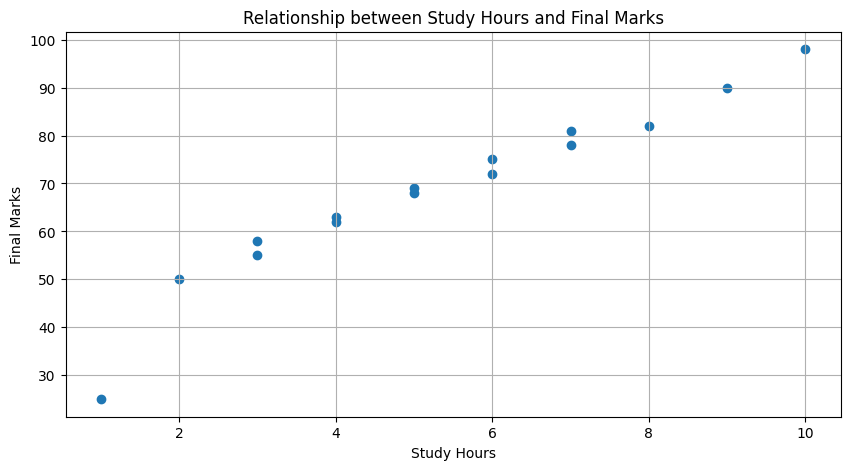

In [ ]:
# Create a scatter plot to visualize the relationship between study hours and final marks.
plt.figure(figsize=(10, 5))
plt.scatter(df['Study_hours'], df['Final_Marks'])
plt.title('Relationship between Study Hours and Final Marks')
plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.grid(True)
plt.show()     # Display the graph

**Step-7: Calculate Covariance**

In [ ]:
# Calculate covariance between study hours and final marks.
covariance = df['Study_hours'].cov(df['Final_Marks'])
print("Covariance between study hours and final marks:", covariance)

Covariance between study hours and final marks: 44.14285714285714


**Step-8: Calculate Covariance Matrix.**

In [ ]:
# Select the numerical columns for covariance analysis and calculate the covariance matrix.
numerical_cols = [ 'Study_hours', 'Attendance','Assignment_Score', 'Final_Marks']
covariance_matrix = df[numerical_cols].cov()
print("Covariance Matrix:", covariance_matrix)

Covariance Matrix:                   Study_hours  Attendance  Assignment_Score  Final_Marks
Study_hours          6.666667   32.595238         36.000000    44.142857
Attendance          32.595238  188.209524        195.328571   239.685714
Assignment_Score    36.000000  195.328571        210.257143   257.328571
Final_Marks         44.142857  239.685714        257.328571   315.400000


**Step-9: Detect outliers using IQR method.**

In [ ]:
# Select Final_Marks column for outlier analysis.
Q1 = df['Final_Marks'].quantile(0.25)
Q3 = df['Final_Marks'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Final_Marks'] < lower_bound) | (df['Final_Marks'] > upper_bound)]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outliers in Final_Marks:")
display(outliers)

Lower Bound: 30.75
Upper Bound: 108.75
Outliers in Final_Marks:


,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
14,115,1,40,35,25


**Step-10: Identify Outliers.**

In [ ]:
# Select records where Final_Marks are below the lower bound or above the upper bound
outliers = df[(df['Final_Marks'] < lower_bound) | (df['Final_Marks'] > upper_bound)]
display(outliers)  # Display the detected outliers records.

,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
14,115,1,40,35,25


**Step-11: Count Outliers.**

In [ ]:
# Count the total number of detected outliers.
outlier_count = len(outliers)
print("Total number of detected outliers:", outlier_count)

Total number of detected outliers: 1


**Step-12: Visualize outliers using box plot.**

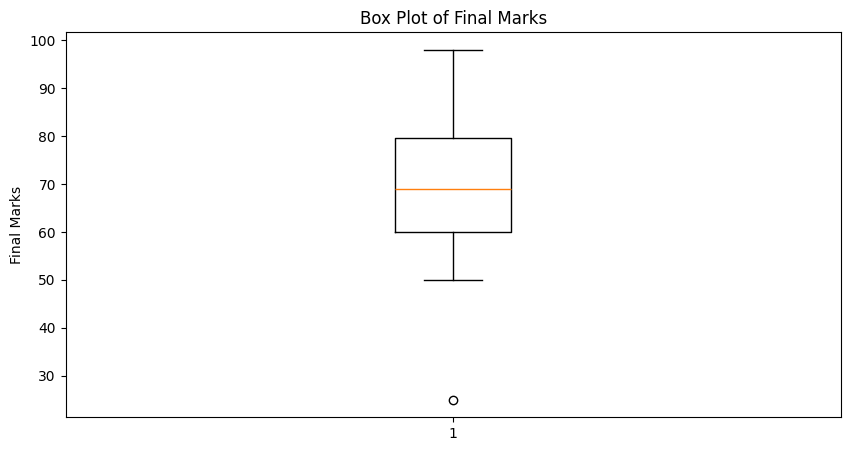

In [ ]:
plt.figure(figsize=(10, 5))
plt.boxplot(df['Final_Marks'])
plt.title('Box Plot of Final Marks')
plt.ylabel('Final Marks')
plt.show()

**Step-13: Create a histogram**

Text(0, 0.5, 'Frequency')

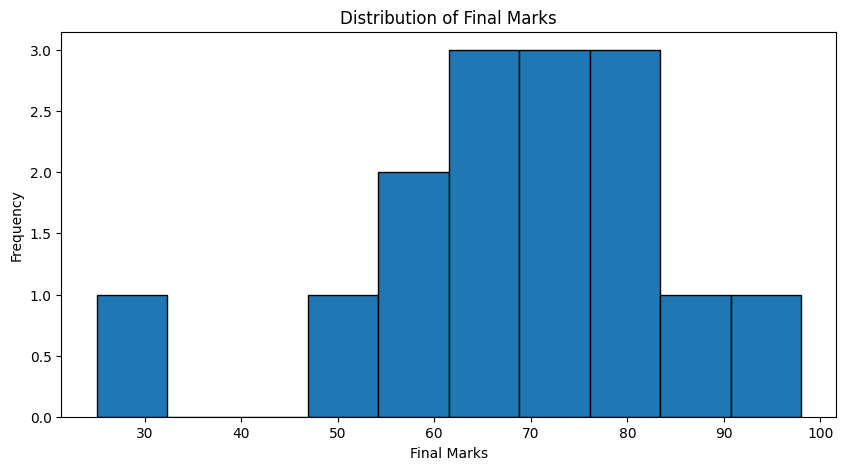

In [ ]:
# Create a histogram to observe the distribution of final marks.
plt.figure(figsize=(10, 5))
plt.hist(df['Final_Marks'], bins=10, edgecolor='black')
plt.title('Distribution of Final Marks')
plt.xlabel('Final Marks')
plt.ylabel('Frequency')

**Step-14: Analyze Distribution Using Skewness.**

In [ ]:
# Calculate the skewness of final marks.
skewness = df['Final_Marks'].skew()
print("Skewness of Final Marks:", skewness)   # Display the skewness value.

Skewness of Final Marks: -0.7383380071904277


**Step-15: Calculate Kurtosis.**

In [ ]:
# Calculate the kurtosis of final marks.
kurtosis = df['Final_Marks'].kurtosis()
print("Kurtosis of Final Marks:", kurtosis)   # Display the kurtosis value.

Kurtosis of Final Marks: 1.4936683306648835


**Step-16: Distribution of study hours.**

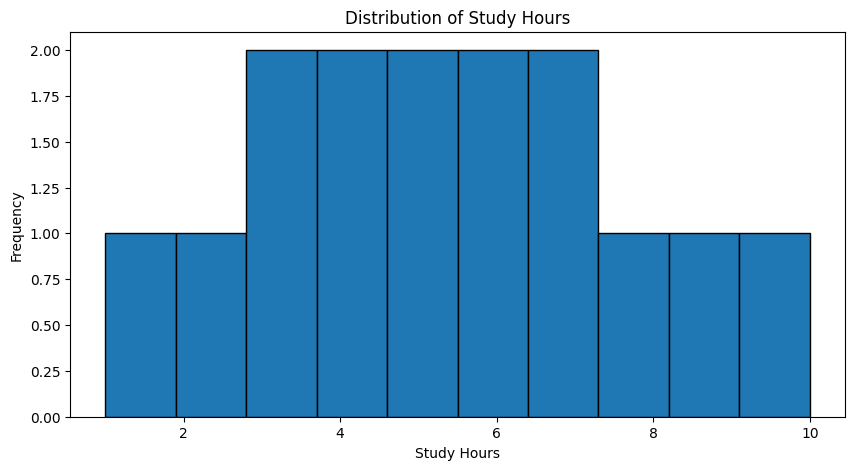

In [ ]:
# Create a histogram for study hours.
plt.figure(figsize=(10, 5))
plt.hist(df['Study_hours'], bins=10, edgecolor='black')
plt.title('Distribution of Study Hours')
plt.xlabel('Study Hours')
plt.ylabel('Frequency')
plt.show()

**Step-17: Compare Variables Using Box Plots.**

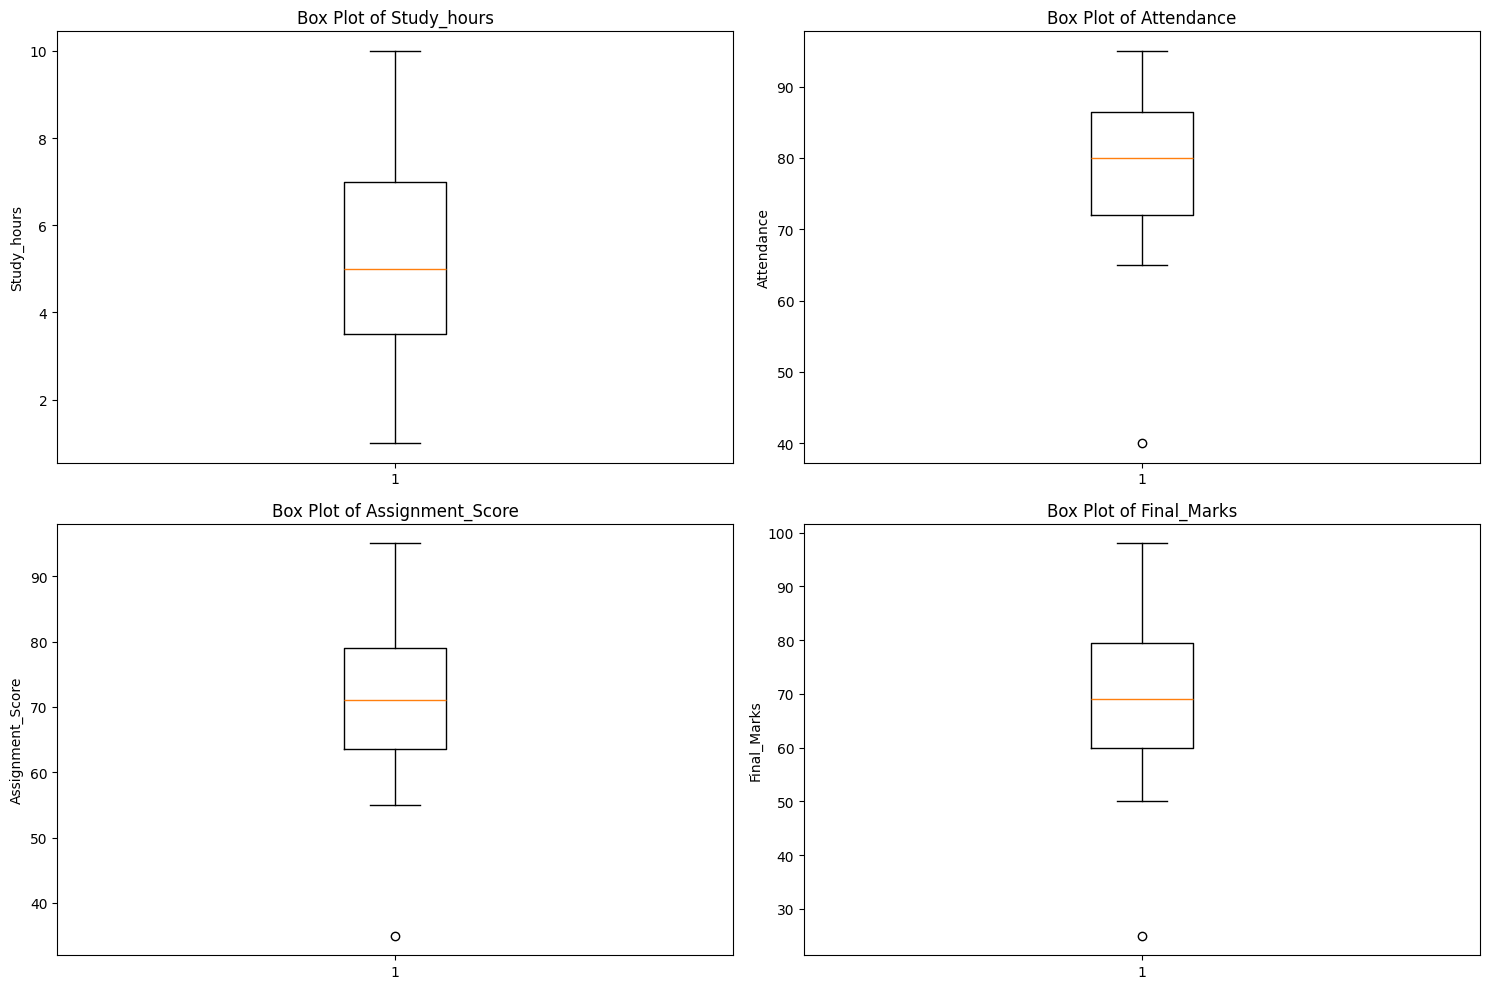

In [ ]:
# Create box plots for multiple numerical variables.
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(2, 2, i + 1) # Arrange plots in a 2x2 grid
    plt.boxplot(df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

**Step-18: Generate a statistical summary.**

In [ ]:
# Generate Statistical Summary.
df.describe()

,Student_ID,Study_hours,Attendance,Assignment_Score,Final_Marks
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,108.000000,5.333333,77.733333,70.400000,68.400000
std,4.472136,2.581989,13.718948,14.500246,17.759504
min,101.000000,1.000000,40.000000,35.000000,25.000000
25%,104.500000,3.500000,72.000000,63.500000,60.000000
50%,108.000000,5.000000,80.000000,71.000000,69.000000
75%,111.500000,7.000000,86.500000,79.000000,79.500000
max,115.000000,10.000000,95.000000,95.000000,98.000000


**Step-19: Save the Analysis Dataset.**

In [ ]:
# Save the updated dataset into CSV file.
df.to_csv("Student_Analysis.csv", index=False)
print("File saved successfully")

File saved successfully


**Step-20: Download the CSV in Google Colab.**

In [ ]:
# import the files module from google colab
from google.colab import files
# download the CSV file to the local computer
files.download("Student_Analysis.csv")
print("File Downloaded Successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File Downloaded Successfully.
